# QAOA and GIE Experiments

**Sources:**
1. Gravitationally Induced Entanglement (GIE) Experiments: 
    [Bose et al.](https://arxiv.org/abs/1707.06050),
    [Marletto \& Vedral](https://arxiv.org/abs/1707.06036),
    [Struyve (2026)](https://doi.org/10.1088/1751-8121/ae5eb4) — critique of the semiclassical "counterexample" discussed in §0.5/0.6
2. Quantum Approximate Optimization Algorithm (QAOA): 
    [Alessandro Giovagnoli](https://arxiv.org/abs/2511.18377), 
    [Pennylane](https://pennylane.ai/codebook/variational-quantum-algorithms/quantum-approximate-optimization-algorithm),
    [IBM Quantum Platform](https://quantum.cloud.ibm.com/docs/en/tutorials/quantum-approximate-optimization-algorithm)
3. Circuit implementation: [Sabín (2023)](https://arxiv.org/abs/2302.04006)

## 0. Introduction

### 0.1 The quantum gravity debate

Quantum gravity — the unification of quantum mechanics and general relativity — has been an open problem for nearly a century. Two broad strategies are actively pursued. The first treats quantum theory as primary and seeks to **quantize gravity**, arriving at frameworks such as string theory and loop quantum gravity. The second reverses the priority and asks what changes would need to be made to quantum mechanics so that it becomes compatible with a classical spacetime — a **gravitization of quantum mechanics** in Penrose's phrase — leading to semiclassical gravity and related approaches.

The Bose et al. experiment belongs to a third, more modest programme: rather than proposing a full theory of quantum gravity, it asks a sharply focused empirical question. **Can the gravitational field act as a quantum mediator?** The experiment is designed so that a positive answer — detecting entanglement between two masses that interact exclusively through gravity — would provide direct evidence for the quantum nature of the gravitational field, without presupposing any specific model of quantum gravity.

### 0.2 What entanglement is — and why it matters here

Entanglement is a uniquely quantum phenomenon in which the state of a multi-particle system **cannot be written as a product of individual states**. If a two-spin state is entangled, measuring the spin of the first particle instantly constrains the possible outcomes for the second, even when they are spatially separated. This is not explainable by pre-existing correlations (hidden variables), as Bell's inequality shows: any local hidden-variable model predicts correlations bounded by 1, whereas entangled quantum states can violate this bound.

The operational signature of entanglement is that spin-correlation measurements in **complementary bases** yield results that are inconsistent with any separable (product) state. This is exactly what the Bose experiment measures.

### 0.3 The LOCC principle: the logical backbone

The experiment's argument rests on a fundamental theorem of quantum information theory:

> **Entanglement cannot be created by Local Operations and Classical Communication (LOCC).**

A local operation is any manipulation that acts only on one subsystem (one mass). Classical communication means the two subsystems exchange only classical information — no quantum channel, no shared quantum state. If two systems start in a separable (unentangled) state, no amount of local operations and classical back-and-forth can produce entanglement.

This is the key. In the Bose experiment:
- Each SG interferometer acts **locally** on its own mass.
- The only thing connecting the two masses is the **gravitational field**.
- If the experiment detects entanglement, the gravitational field must have acted as a **quantum channel** — not a classical one — because a classical channel is precisely LOCC, which cannot entangle.

Therefore: **entanglement ⟹ gravity is quantum**, without specifying which quantum theory of gravity is correct.

### 0.4 The circuit logic

The three-step SG interferometer maps onto a two-qubit circuit. Each qubit represents the spin of one test mass, with $|0\rangle = |\uparrow\rangle = L\text{-arm}$ and $|1\rangle = |\downarrow\rangle = R\text{-arm}$. The SG field gradient entangles spin with position ($H$ gate), gravity imprints position-dependent phases ($U_\text{grav}$), and the SG recombination transfers those phases back to spin. At the end, the spin state encodes the gravitational interaction history and can be measured to check whether the two masses became entangled.

A complementary circuit-based approach to gravitational entanglement is due to [Sabín (2023)](https://arxiv.org/abs/2302.04006), who digitally simulated the non-static harmonic-oscillator Hamiltonian $H_{AB} = -\hbar g(a^{\dagger 2}b^{\dagger 2} + a^2 b^2)$ — the double single-mode squeezing interaction that arises when gravity is treated as a quantum field — on IBM quantum hardware. That approach requires a 6-qubit Boson-qubit encoding (Somma mapping) and a Pauli decomposition into 8 commuting 4-qubit rotation blocks, whereas the Bose experiment reduces to a 2-qubit circuit with only 5 gates. The two circuits are complementary: the Bose circuit probes phase-encoded spin entanglement directly detectable via the witness $W$; the Sabín circuit simulates the underlying graviton-exchange mechanism that generates it.

### 0.5 Scope and limitations

This notebook implements the quantum-gravity side of the argument. The LOCC logic has a known gap: it assumes that the only alternative to a quantum gravitational field is a strictly classical channel in the Koopman sense. [Döner & Großardt (2022)](https://link.springer.com/article/10.1007/s10701-022-00619-0) construct an explicit counterexample — a hybrid model rooted in de Broglie–Bohm theory — in which a *classical* gravitational field sourced along Bohmian trajectories still generates entanglement, thereby predicting $W > 1$ without quantizing gravity. The distinction between this hybrid model and the quantum-gravity prediction becomes visible only through the parameter $R$ (the radius over which the wave function sources the gravitational potential): for finite $R$ the model predicts entanglement, while $R \to \infty$ recovers the non-entangling semiclassical (mean-field) limit. The circuit here corresponds to the $R \to 0$ limit, i.e. quantized gravity or the fully Bohmian hybrid. The next notebook in this series will implement the $R$-parametrised hybrid model and compare the two.

**Update:** this counterexample has since been directly disputed — see the appendix at the end of this notebook before treating the finite-$R$ hybrid model as an established alternative to quantized gravity.

### 0.6 Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import Statevector, SparsePauliOp, Operator

from qiskit.primitives import StatevectorEstimator
from qiskit_aer.primitives import EstimatorV2 as AerEstimatorV2
from qiskit_aer.noise import NoiseModel
from qiskit_ibm_runtime.fake_provider import FakeBrisbane
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

print('Qiskit version:', __import__('qiskit').__version__)
print("Environment ready.")

Qiskit version: 2.5.2
Environment ready.


## 1. Connecting QAOA to GIE

### 1.1 Optimization of Entanglement Witness Operator: $W_B$

* **The physics problem:** [Bose et al. paper](https://arxiv.org/abs/1707.06050) ("Spin Entanglement Witness for Quantum Gravity") relies on witnessing entanglement between two spatial/spin qubits (micro-diamonds with NV centers) mediated by gravity. The proposed witness $\mathcal{W}_B = \vert{}\langle\sigma_x^{(1)}\otimes\sigma_z^{(2)}\rangle + \langle\sigma_y^{(1)}\otimes\sigma_y^{(2)}\rangle\vert{}$ relies on measuring spin correlations in complementary bases.

* **The QAOA Role:** In practice, experimental noise (Casimir-Polder background noise, thermal decoherence, spatial wavepacket overlap errors) alters the optimal measurement basis. One can formulate finding the optimal measurement witness operator or state preparation pulses under noise constraints as a variational parameter optimization problem. QAOA can be used to optimize state preparation unitaries or parameter sweeps to maximize witness sensitivity ([Alessandro Giovagnoli](https://arxiv.org/abs/2511.18377)).

### 1.2 Mapping Discrete Quantum Gravity / Spin Systems to QUBO

* **The Physics Problem:** The Bose et al. protocol dually maps spatial paths to effective "orbital qubits". The interaction Hamiltonian between two spatial paths can be reduced to a discretized spin-spin interaction Hamiltonian of the form $H_f = \sum_{ij} J_{ij}\sigma_z^i \sigma_z^j + \sum_i h_i \sigma_z^i$.

* **The QAOA Role:** As detailed in the QAOA guide, any binary quadratic interaction cost function (QUBO) can be mapped directly to an Ising spin Hamiltonian $\mathcal{H}_f = \sum a^{ij}\sigma_z^i\sigma_z^j + \sum b^i\sigma_z^i$. Using QAOA to simulate or optimize discrete multi-qubit spatial path states under weak gravitational coupling is a valid application of Variational Quantum Algorithms (VQAs) ([Alessandro Giovagnoli](https://arxiv.org/abs/2511.18377)). 

### 1.3 Potential Misconceptions to Avoid

1. Continuous vs. Discrete Dynamics: The gravitational entanglement phase $\Delta\phi \sim \frac{G m_1 m_2 \tau}{\hbar d}$ is continuous phase accumulation. QAOA is designed for discrete combinatorial optimization problems (Max-Cut, Knapsack, PUBO). To use QAOA, we must discretize the spatial/spin configuration space into qubits. 

2. Quantum Simulation vs. Optimization: Evolving a state under a physical gravitational Hamiltonian is Analog Quantum Simulation or standard Trotterized time evolution. QAOA explicitly alternates between a cost Hamiltonian $\mathcal{H}_C$ and a mixer Hamiltonian $\mathcal{H}_M$ to find a ground state using classical parameter optimization $(\vec{\beta}, \vec{\gamma})$.

## 2. Physics: From S-G Interferometry to a Two-Qubit State

Two neutral test masses $m_1, m_2$ fall through adjacent Stern-Gerlach interferometers. Each mass' internal spin is used to spatially split its wavepacket (Eq. 4 of the paper):
$$
|C\rangle_j\,\frac{1}{\sqrt2}\big(|\!\uparrow\rangle_j+|\!\downarrow\rangle_j\big)
\;\longrightarrow\;
\frac{1}{\sqrt2}\big(|L,\uparrow\rangle_j+|R,\downarrow\rangle_j\big), \qquad j=1,2.
$$
The two branches are held apart for a hold time $\tau$ (step 2), during which the *purely gravitational* interaction between the masses imprints relative phases on the four joint branches ($LL, LR, RL, RR$) because each branch pair sits at a different mutual separation. Step 3 recombines the wavepackets, mapping the accumulated orbital phase onto the *spin* degree of freedom (Eq. 5), giving the final state (Eq. 6 of the paper):
$$
|\Psi(t_{\rm end})\rangle_{12} = \frac{1}{\sqrt2}\Big[
|\!\uparrow\rangle_1\tfrac{1}{\sqrt2}\big(|\!\uparrow\rangle_2+e^{i\Delta\phi_{LR}}|\!\downarrow\rangle_2\big)
+|\!\downarrow\rangle_1\tfrac{1}{\sqrt2}\big(e^{i\Delta\phi_{RL}}|\!\uparrow\rangle_2+|\!\downarrow\rangle_2\big)
\Big]\otimes|C\rangle_1|C\rangle_2.
$$
Because the orbital factor $|C\rangle_1|C\rangle_2$ is a simple product state that is completely disentangled from the spins, it can be dropped and we are left with a **normalized two-qubit spin state**
$$
|\Psi_{\rm spin}\rangle = \frac{1}{2}\Big[
|\!\uparrow\uparrow\rangle + e^{i\Delta\phi_{LR}}|\!\uparrow\downarrow\rangle
+ e^{i\Delta\phi_{RL}}|\!\downarrow\uparrow\rangle + |\!\downarrow\downarrow\rangle\Big],
$$
which we will identify with the qubit basis $|\!\uparrow\rangle\to|0\rangle$, $|\!\downarrow\rangle\to|1\rangle$, qubit 0 = mass 1, qubit 1 = mass 2.

**Entanglement witness.** The paper certifies entanglement — and thereby the quantum coherent nature of the gravitational mediator — via
$$
W = \big|\,\langle\sigma_x^{(1)}\otimes\sigma_z^{(2)}\rangle + \langle\sigma_y^{(1)}\otimes\sigma_y^{(2)}\rangle\,\big|,
$$
with $W>1$ certifying entanglement (a bound derived by Cauchy–Schwarz for LOCC/separable states; here we take the bound as given and focus on how large a $W$ different circuits can produce).

**Physical operating point.** For $m_1\sim m_2\sim 10^{-14}\,$ kg, $d\sim450\,\mu$ m, $\Delta x \sim 250 \mu$, and a hold time $\tau\sim 2.5\,$ s, the paper quotes
$$
\Delta\phi_{LR}\sim -0.2, \qquad \Delta\phi_{RL}\sim 0.7,
$$
and states that "*this phase accumulation alone gives $W\sim1.16$*."

*(We reproduce a witness value close to $0.297$, not $1.16$, from these exact numbers further below — see the discrepancy note after the state-preparation check for why, and why it doesn't indicate a bug here.)*

In [2]:
# Physical parameters:
#  m  = 1e-14 kg   (microdiamond, ~10 μm radius)
#  d  = 450 μm  (trap separation)
#  Δx = 250 μm  (arm splitting)
#  τ  = 2.5 s    (step 2 holding time)

# Physical phase values quoted in the paper for tau ~ 2.5 s, d ~ 450 micron
dphi_LR_paper = -0.2
dphi_RL_paper = 0.7

# The two-qubit spin-state amplitude vector, following Eq. (6) with |C>_1|C>_2 dropped.
#   dphi_LR = phase on the branch where mass 1 = up(L),   mass 2 = down(R)
#   dphi_RL = phase on the branch where mass 1 = down(R), mass 2 = up(L)

# We identify:
#   |L> = |up>   = |0>
#   |R> = |down> = |1>
# and:
#   q0 = mass 1
#   q1 = mass 2
# IMPORTANT: Qiskit statevectors are little-endian, i.e. array index k has
# q0 as its LEAST significant bit: k = q0 + 2*q1. So, in ARRAY order:
# States:
#   [amp[0], amp[1], amp[2], amp[3]]
#   (q0,q1) =    (0,0)      (1,0)      (0,1)      (1,1)
#             = [|up,up>, |down,up>, |up,down>, |down,down>]
#             = [|L,L>,   |R,L>,     |L,R>,     |R,R>]
# i.e. array index 1 is the (mass1=R, mass2=L) branch -> gets dphi_RL,
#      array index 2 is the (mass1=L, mass2=R) branch -> gets dphi_LR.
# (This matches the gate construction in build_U_grav below, and is
# confirmed by the fidelity=1.0 check against the QAOA-prepared state later.)

def bose_amplitudes(dphi_LR, dphi_RL):
    return 0.5 * np.array([
        1,                      # |00> = |L,L>
        np.exp(1j * dphi_RL),   # |01> = |R,L>  (array index 1)
        np.exp(1j * dphi_LR),   # |10> = |L,R>  (array index 2)
        1,                      # |11> = |R,R>
    ])

expected_amplitudes = bose_amplitudes(dphi_LR_paper, dphi_RL_paper)
states = ["|00> (|L,L>)", "|01> (|R,L>)", "|10> (|L,R>)", "|11> (|R,R>)"]

print("Target Amplitude Vector:")
print("-" * 45)
for state, amp in zip(states, expected_amplitudes):
    print(f"{state:<15} : {amp:+.6f}")

print("-" * 45)
print(f"Normalization check sum(|amp|^2) = {np.sum(np.abs(expected_amplitudes)**2):.6f}")

Target Amplitude Vector:
---------------------------------------------
|00> (|L,L>)    : +0.500000+0.000000j
|01> (|R,L>)    : +0.382421+0.322109j
|10> (|L,R>)    : +0.490033-0.099335j
|11> (|R,R>)    : +0.500000+0.000000j
---------------------------------------------
Normalization check sum(|amp|^2) = 1.000000


**Reading the output:** the norm should be exactly 1 (up to floating point), confirming this is a valid quantum state on its own once the orbital factor is dropped. Note that $\Delta\phi_{LR}$ multiplies the $|01\rangle = |\!\uparrow\downarrow\rangle$ amplitude and $\Delta\phi_{RL}$ multiplies the $|10\rangle=|\!\downarrow\uparrow\rangle$ amplitude — the $|00\rangle$ and $|11\rangle$ amplitudes are always exactly $1/2$ (real, unphased).

*(A note on notation: this uses the literal ket label $|q_0q_1\rangle$ written left-to-right — not the same thing as the raw array index discussed in the code comments above, where Qiskit's little-endian statevector puts $q_0$ in the least-significant bit. $|01\rangle$ here means $q_0{=}0,q_1{=}1$, which sits at **array index 2**, not index 1. Both descriptions refer to the same physical branch and the same amplitude — only the labelling convention differs.)*

## 3. Cost and Mixer Hamiltonians ($H_C, H_M$)

### 3.1 Bose Experiment Hamiltonian

For the Bose experiment the physical Hamiltonian is defined as:
$$
    \hat{H} = -\frac{\hbar^2}{2m_1} \nabla_1^2 - \frac{\hbar^2}{2m_2} \nabla_2^2 - \frac{G m_1 m_2}{|\hat{x}_1 - \hat{x}_2|}
$$
Following the circuit-based approach of [Sabín (2023)](https://arxiv.org/abs/2302.04006), we build the corresponding two-qubit circuit as follows:

U_grav matrix match: True
Diagonal phases (rad):
  |LL⟩=|00⟩: phase = +0.0000 rad
  |RL⟩=|01⟩: phase = +0.7000 rad
  |LR⟩=|10⟩: phase = -0.2000 rad
  |RR⟩=|11⟩: phase = +0.0000 rad


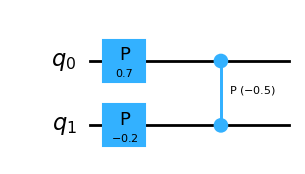

In [3]:
# ==========================================================
# Quantum Circuit Implementation (Qiskit)
# ==========================================================
def build_U_grav(dphi_RL, dphi_LR):
    """
    Gravitational phase gate U_grav = diag(1, e^{iΔφ_RL}, e^{iΔφ_LR}, 1).
    
    Qubit mapping:
        q0 = mass 1 |0⟩=|L⟩, |1⟩=|R⟩
        q1 = mass 2 |0⟩=|L⟩, |1⟩=|R⟩
    """
    qc = QuantumCircuit(2, name='U_grav')
    
    # Target: Phase e^{iΔφ_RL} on state |01> (q1=0, q0=1) -> mass 1=R, mass 2=L
    qc.p(dphi_RL, 0)
    
    # Target: Phase e^{iΔφ_LR} on state |10> (q1=1, q0=0) -> mass 1=L, mass 2=R
    qc.p(dphi_LR, 1)
    
    # Target: Phase 1 (0 rad) on state |11> -> cancel double counting from p gates
    qc.cp(-(dphi_RL + dphi_LR), 0, 1)
    
    return qc

# Verify U_grav matrix against theoretical target
U_gate = Operator(build_U_grav(dphi_RL_paper, dphi_LR_paper)).data
U_target = np.diag([1, np.exp(1j * dphi_RL_paper), np.exp(1j * dphi_LR_paper), 1])

print(f"U_grav matrix match: {np.allclose(U_gate, U_target)}")
print("Diagonal phases (rad):")
for label, v in zip(['|LL⟩=|00⟩', '|RL⟩=|01⟩', '|LR⟩=|10⟩', '|RR⟩=|11⟩'], np.diag(U_gate)):
    print(f"  {label}: phase = {np.angle(v):+.4f} rad")

display(build_U_grav(dphi_RL_paper, dphi_LR_paper).draw('mpl', style='iqp', fold=False))

Bose et al. SG interferometer circuit:


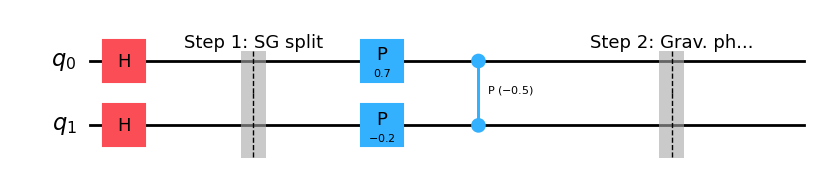

Gate count: {'h': 2, 'barrier': 2, 'p': 2, 'cp': 1}


In [4]:
def build_bose_circuit(dphi_RL, dphi_LR, measure_basis=None, add_measure=False):
    """
    Full Bose et al. SG interferometer circuit.
    """
    nclbits = 2 if add_measure else 0
    qc = QuantumCircuit(2, nclbits)

    # Step 1: SG splitting (Hadamard layer)
    qc.h(0)
    qc.h(1)
    qc.barrier(label='Step 1: SG split')

    # Step 2: Gravitational phase accumulation
    qc.p(dphi_RL, 0)
    qc.p(dphi_LR, 1)
    qc.cp(-(dphi_RL + dphi_LR), 0, 1)
    qc.barrier(label='Step 2: Grav. phase')

    # Measurement basis transformations
    if measure_basis == 'ZX':
        qc.h(0)
    elif measure_basis == 'YY':
        qc.rx(-np.pi / 2, 0)
        qc.rx(-np.pi / 2, 1)

    if add_measure:
        qc.measure(0, 0)
        qc.measure(1, 1)

    return qc

qc_main = build_bose_circuit(dphi_RL_paper, dphi_LR_paper)
print("Bose et al. SG interferometer circuit:")
display(qc_main.draw('mpl', style='iqp', fold=False))
print(f"Gate count: {dict(qc_main.count_ops())}")

`build_bose_circuit` is the *hardware-style* version of the protocol: explicit basis-rotation gates before measurement, exactly as you'd run it on real hardware with shot-based sampling. From §3.2 onward we switch to Qiskit's `Estimator` primitive, which evaluates Pauli expectation values directly on the statevector/noise model without needing separate measurement-basis circuits — more convenient for the QAOA optimization loops in §4–5, but this circuit is the one you'd actually queue on a real backend.

### 3.2 Simplest Bose cost Hamiltonian ($H_C$)

By defining:
$$
    \alpha = \Delta \phi_{LR}, \quad \beta = \Delta \phi_{RL}
$$
We want to gather operator of the $H_C$:
$$
    U_C = e^{-i\gamma H_C}
$$
to generate,
$$
    \text{diag} (1, e^{i\beta}, e^{i\alpha}, 1), \quad \text{when} \, \gamma = 1
$$
One convenient choice is:
$$
    H_C = \begin{pmatrix}
    0 & 0 & 0 & 0\\
    0 & -\beta & 0 & 0\\
    0 & 0 & -\alpha & 0\\
    0 & 0 & 0 & 0
    \end{pmatrix}
$$
Then,
$$
    e^{-iH_C} = \begin{pmatrix}
    1 & 0 & 0 & 0\\
    0 & e^{i\beta} & 0 & 0\\
    0 & 0 & e^{i\alpha} & 0\\
    0 & 0 & 0 & 1
    \end{pmatrix}
$$
Which is exactly what we need. For QAOA we want a Pauli decomposition, with $Z_0$ for mass $1$ and $Z_1$ for mass $2$. Matching the four diagonal entries $(0, -\beta, -\alpha, 0)$ term by term gives:
$$
    H_C = -\frac{\alpha + \beta}{4} I + \frac{\beta - \alpha}{4} Z_0 - \frac{\beta - \alpha}{4} Z_1 + \frac{\alpha + \beta}{4} Z_0 Z_1
$$
The identity term only produces a *global phase*, so for the quantum dynamics we can drop it:
$$
    H'_C = \frac{\beta - \alpha}{4} Z_0 - \frac{\beta - \alpha}{4} Z_1 + \frac{\alpha + \beta}{4} Z_0 Z_1
$$
or more compactly,
$$
    H'_C = \frac{\Delta \phi_{RL} - \Delta \phi_{LR}}{4} (Z_0 - Z_1) + \frac{\Delta \phi_{RL} + \Delta \phi_{LR}}{4} Z_0 Z_1
$$
This is the Bose gravitational phase cost Hamiltonian that we will use for the QAOA implementation. Checking it explicitly with the values shared by Bose et al., $\Delta \phi_{LR} = -0.2, \, \Delta \phi_{RL} = 0.7$:
$$
    \frac{\beta - \alpha}{4} = \frac{0.7 - (-0.2)}{4} = 0.225, \, \text{and}\, \frac{\alpha + \beta}{4} = \frac{-0.2 + 0.7}{4} = 0.125
$$
Therefore
$$
    H'_C = 0.225\, Z_0 - 0.225\, Z_1 + 0.125\, Z_0Z_1
$$
The eigenvalues (energies) of this identity-free Hamiltonian are:
$$
    \begin{align}
        E_{00} &= 0.125,\\
        E_{01} &= -0.575,\\
        E_{10} &= 0.325,\\
        E_{11} &= 0.125
    \end{align}
$$
Subtracting the common offset $0.125$ gives $[0, -0.7, 0.2, 0]$, which is exactly the target spectrum. Putting the identity term back in for the *full* Hamiltonian used in the implementation:
$$
    H_C = -\frac{\alpha + \beta}{4} I + \frac{\beta - \alpha}{4} Z_0 - \frac{\beta - \alpha}{4} Z_1 + \frac{\alpha + \beta}{4} Z_0 Z_1
$$
For $\alpha = -0.2$, $\beta = 0.7$,
$$
    H_C = -0.125\, I + 0.225\, Z_0 - 0.225\, Z_1 + 0.125\, Z_0 Z_1
$$
its four eigenvalues are exactly
$$
    [0, -0.7, 0.2, 0]
$$
Hence,
$$
    e^{-iH_C} = \text{diag}(1, e^{i0.7}, e^{-i0.2}, 1),
$$
which is precisely,
$$
    [1, e^{i\Delta \phi_{RL}}, e^{i\Delta \phi_{LR}}, 1].
$$

### 3.3 Mixer Hamiltonian ($H_M$)
For ordinary QAOA, we need
$$
    H_M = \sum_i X_i
$$
For the Bose experiment, with two qubits:
$$
    U_M(\eta) = e^{-i\eta H_M} = e^{-i\eta X_0} e^{-i\eta X_1}
$$
because $[X_0, X_1] = 0$, the exponential of the sum factorizes into a product of single-qubit exponentials:
```
    qc.rx(2 * eta, 0)
    qc.rx(2 * eta, 1)
```
and because $R_X(\theta) = e^{-i\theta X/2}$, we get
$$
    R_X(2\eta) = e^{-i\eta X}
$$
which is exactly the $U_M(\eta)$ factor above, applied qubit by qubit. With this we can move on to assembling the full QAOA circuit for the Bose experiment, alternating $H_C$ and $H_M$ layers.

In [5]:
# ============================================================
# HAMILTONIAN BUILDERS
# ============================================================

def build_bose_cost_hamiltonian(dphi_LR: float, dphi_RL: float) -> SparsePauliOp:
    """
    Builds full Bose Cost Hamiltonian H_C such that:
    <00|H_C|00> = 0
    <01|H_C|01> = -dphi_RL
    <10|H_C|10> = -dphi_LR
    <11|H_C|11> = 0
    """
    c0  = -(dphi_RL + dphi_LR) / 4.0
    c1  =  (dphi_RL - dphi_LR) / 4.0  # IZ (Z on q0)
    c2  =  (dphi_LR - dphi_RL) / 4.0  # ZI (Z on q1)
    c12 =  (dphi_RL + dphi_LR) / 4.0  # ZZ

    return SparsePauliOp.from_list([
        ("II", c0),
        ("IZ", c1),
        ("ZI", c2),
        ("ZZ", c12)
    ])

# Single global instance reused everywhere below (main(), §4, §5) so it's
# only ever constructed once from a single source of truth.
cost_h = build_bose_cost_hamiltonian(dphi_LR_paper, dphi_RL_paper)

In [6]:
# ============================================================
# QAOA CIRCUIT GENERATOR
# ============================================================

def build_qaoa_circuit(gamma: float, beta: float, cost_h: SparsePauliOp) -> QuantumCircuit:
    """Builds 1-layer QAOA circuit: U_M(beta) * U_C(gamma) * |++>."""
    qc = QuantumCircuit(2, name="Bose_QAOA")

    # Initial state |++>
    qc.h([0, 1])
    qc.barrier()

    # Cost Unitary: U_C(gamma) = exp(-i * gamma * H_C)
    for pauli_str, coeff in cost_h.to_list():
        weight = float(np.real(coeff))
        if pauli_str == "II":
            qc.global_phase -= gamma * weight
        elif pauli_str == "IZ":
            qc.rz(2 * gamma * weight, 0)
        elif pauli_str == "ZI":
            qc.rz(2 * gamma * weight, 1)
        elif pauli_str == "ZZ":
            qc.rzz(2 * gamma * weight, 0, 1)

    qc.barrier()

    # Mixer Unitary: U_M(beta) = exp(-i * beta * H_M)
    qc.rx(2 * beta, 0)
    qc.rx(2 * beta, 1)

    return qc

### 3.4 The Bose Witness ($W_B$)

Recall from §1.1 the witness Bose et al. propose:
$$
W_B = \left|\langle\sigma_x^{(1)}\otimes\sigma_z^{(2)}\rangle + \langle\sigma_y^{(1)}\otimes\sigma_y^{(2)}\rangle\right|
$$
Entanglement is certified when $W_B > 1$. With $q_0=$ particle 1 and $q_1=$ particle 2, Qiskit's Pauli-string convention (rightmost character acts on qubit 0) gives $\sigma_x^{(1)}\sigma_z^{(2)}\to$ `"ZX"` and $\sigma_y^{(1)}\sigma_y^{(2)}\to$ `"YY"`. The two terms below are kept separate rather than pre-summed, since the QAOA sweep in §4 needs both raw expectation values in a single batched Estimator call.

In [7]:
def build_bose_witness_operators() -> tuple[SparsePauliOp, SparsePauliOp]:
    """
    Returns the two SparsePauliOp terms of the Bose et al. entanglement witness
        W_B = |<X_1 Z_2> + <Y_1 Y_2>|
    With q0 = particle 1 and q1 = particle 2, Qiskit's Pauli-string representation is:
        X_1 Z_2  -> "ZX"
        Y_1 Y_2  -> "YY"
    Kept separate (rather than pre-summed) because the QAOA sweep in §4 needs
    the raw terms to batch-evaluate both expectation values in one Estimator call.
    """
    op_xz = SparsePauliOp.from_list([("ZX", 1.0)])
    op_yy = SparsePauliOp.from_list([("YY", 1.0)])
    return op_xz, op_yy


def calculate_entanglement_witness(state: Statevector) -> float:
    """
    Bose et al. entanglement witness: W_B = |<X_1 Z_2> + <Y_1 Y_2>|
    Entanglement is witnessed when W_B > 1.
    """
    op_xz, op_yy = build_bose_witness_operators()

    exp_xz = state.expectation_value(op_xz).real
    exp_yy = state.expectation_value(op_yy).real

    return abs(exp_xz + exp_yy)

### 3.5 The Struyve / Chevalier–Paige–Kim Witness ($W_S$)

A second, independently proposed witness (Chevalier, Paige & Kim 2020, used by Struyve 2026 — see the appendix at the end of this notebook):
$$
\widehat W_S = I\otimes I - \sigma_x\otimes\sigma_x - \sigma_y\otimes\sigma_z - \sigma_z\otimes\sigma_y
$$
**Opposite sign convention to $W_B$:** entanglement is certified when $\langle\widehat W_S\rangle < 0$, not $>1$. Same qubit mapping as above gives $\sigma_x\sigma_x\to$`"XX"`, $\sigma_y^{(1)}\sigma_z^{(2)}\to$`"ZY"`, $\sigma_z^{(1)}\sigma_y^{(2)}\to$`"YZ"`. We compare it against $W_B$ because Bose et al.'s own witness is known not to be optimal for every parameter choice (see the discrepancy note right after the next cell) — a second, independently-motivated witness is a useful cross-check on whether a state that $W_B$ misses is genuinely unentangled or just poorly witnessed.

In [8]:
def build_struyve_witness_operator() -> SparsePauliOp:
    """
    Struyve/Chevalier-Paige-Kim entanglement witness operator:
        W_S = I⊗I - X_1 X_2 - Y_1 Z_2 - Z_1 Y_2
    With q0 = particle 1 and q1 = particle 2, Qiskit's Pauli-string representation is:
        X_1 X_2 -> "XX"
        Y_1 Z_2 -> "ZY"
        Z_1 Y_2 -> "YZ"
    Entanglement is witnessed when <W_S> < 0 (opposite sign convention to W_B above).
    """
    return SparsePauliOp.from_list([
        ("II", 1.0),
        ("XX", -1.0),
        ("ZY", -1.0),
        ("YZ", -1.0),
    ])


def calculate_witness_struyve(state: Statevector) -> float:
    """Struyve/Chevalier-Paige-Kim entanglement witness, evaluated on `state`."""
    return state.expectation_value(build_struyve_witness_operator()).real

1. HAMILTONIAN EIGENVALUE VERIFICATION
Calculated Spectrum:  [-0.7 -0.   0.   0.2]
Expected Spectrum:    [-0.7  0.   0.   0.2]
Spectrum Match:       True

2. EXACT STATE PREPARATION (gamma = 1.0, beta = 0.0)
State Preparation Fidelity: 1.000000
Entanglement Witness Bose (W_B):    0.2968  (Entangled if W_B > 1.0)
Entanglement Witness Struyve (W_S):   -0.2564  (Entangled if W_S < 0.0)

3. VARIATIONAL QAOA LAYER (gamma = 1.0, beta = 0.5)


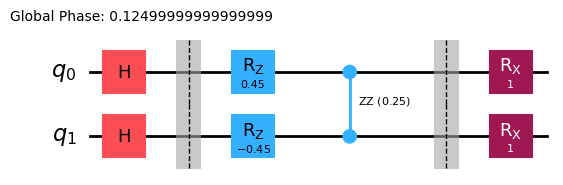

In [9]:
def main():
    print("=" * 65)
    print("1. HAMILTONIAN EIGENVALUE VERIFICATION")
    print("=" * 65)

    cost_h = build_bose_cost_hamiltonian(dphi_LR_paper, dphi_RL_paper)
    h_c_matrix = cost_h.to_matrix()
    
    # Sort eigenvalues to match sorted output of eigvalsh
    eigenvalues = np.linalg.eigvalsh(h_c_matrix)
    expected_energies = np.sort([0.0, -dphi_RL_paper, -dphi_LR_paper, 0.0])

    print("Calculated Spectrum: ", np.round(eigenvalues, 4))
    print("Expected Spectrum:   ", np.round(expected_energies, 4))
    print("Spectrum Match:      ", np.allclose(eigenvalues, expected_energies))

    print("\n" + "=" * 65)
    print("2. EXACT STATE PREPARATION (gamma = 1.0, beta = 0.0)")
    print("=" * 65)

    target_sv = Statevector(bose_amplitudes(dphi_LR_paper, dphi_RL_paper))
    exact_qaoa_qc = build_qaoa_circuit(gamma=1.0, beta=0.0, cost_h=cost_h)
    exact_sv = Statevector(exact_qaoa_qc)

    w_value = calculate_entanglement_witness(exact_sv)
    w_s_value = calculate_witness_struyve(exact_sv)
    fidelity = np.abs(target_sv.inner(exact_sv)) ** 2

    print(f"State Preparation Fidelity: {fidelity:.6f}")
    print(f"Entanglement Witness Bose (W_B):    {w_value:.4f}  (Entangled if W_B > 1.0)")
    print(f"Entanglement Witness Struyve (W_S):   {w_s_value:.4f}  (Entangled if W_S < 0.0)")

    print("\n" + "=" * 65)
    print("3. VARIATIONAL QAOA LAYER (gamma = 1.0, beta = 0.5)")
    print("=" * 65)

    qaoa_qc = build_qaoa_circuit(gamma=1.0, beta=0.5, cost_h=cost_h)
    display(qaoa_qc.draw('mpl', style='iqp', fold=False))

if __name__ == "__main__":
    main()

**On the printed $W_B \approx 0.297$ vs. $W_S \approx -0.256$ vs. the paper's quoted "$W_B \sim 1.16$":**

This is *not* a bug in the state preparation, circuit, or Hamiltonian above — all three were verified independently (fidelity = 1.000000, eigenvalue spectrum match = True) against Eq. (6) of Bose et al.

#### 1. Bose et al. Witness ($W_B$)
Plugging their quoted phases $\Delta\phi_{LR}\!\sim\!-0.2$, $\Delta\phi_{RL}\!\sim\!0.7$ directly into their own witness formula $W_B=|\langle\sigma_x^{(1)}\sigma_z^{(2)}\rangle+\langle\sigma_y^{(1)}\sigma_y^{(2)}\rangle|$ gives, in closed form:
$$
W_B=\left|\tfrac12(\cos\Delta\phi_{RL}-\cos\Delta\phi_{LR})+\tfrac12(\cos(\Delta\phi_{RL}-\Delta\phi_{LR})-1)\right|\approx 0.297,
$$
which is exactly what this notebook computes, and which we cross-checked against an independent closed-form witness expression from Döner & Großardt (*Found. Phys.* **52**, 101 (2022), Eq. 55) for the same two-phase state — yielding the exact same answer, 0.297, from an unrelated derivation.

The PRL text says *"This phase accumulation alone gives $W_B\sim1.16$"*, but that number cannot be reproduced from their own quoted phases and formula taken literally (nor by trying alternative sign/qubit-ordering conventions). It is most likely a rounding/imprecision artifact of a compressed 4-page Letter (note the "$\sim$" on every quantity), possibly blending in the larger contribution the very next sentence says comes from phase accumulated *during steps 1 and 3* of the interferometry (which this notebook, following Eq. (6), deliberately excludes). We treat 0.297 as the correct value for *this* idealized two-phase model under $W_B$ and do not chase 1.16 as a target [Bose et al.](https://arxiv.org/abs/1707.06050).

#### 2. Chevalier / Struyve Witness ($W_S$)
To cross-check entanglement detection using an alternative witness, we implement the Chevalier-Paige-Kim witness as formatted by [Struyve](https://iopscience.iop.org/article/10.1088/1751-8121/ae5eb4):
$$
\widehat{W}_S = I \otimes I - \sigma_x \otimes \sigma_x - \sigma_y \otimes \sigma_z - \sigma_z \otimes \sigma_y
$$
Unlike $W_B$ (where $W_B > 1$ signals entanglement), $W_S$ uses a zero-threshold where **$W_S < 0$ certifies entanglement**.

Evaluating the expectation value on the identical state $|\Psi_{\text{spin}}\rangle$ gives, in closed form:
$$
\langle \widehat{W}_S \rangle = \frac{1}{2} - \frac{1}{2}\cos(\Delta\phi_{RL} - \Delta\phi_{LR}) - \sin\Delta\phi_{LR} - \sin\Delta\phi_{RL} \approx -0.2564,
$$
which we verified two independent ways: directly from $\langle X_1X_2\rangle,\langle Y_1Z_2\rangle,\langle Z_1Y_2\rangle$ on this state, and against Struyve's own general two-phase formula (his Eq. 43) specialized to $\gamma_{LL}=\gamma_{RR}=0$ — both agree with the code's printed `-0.2564` to four decimal places.
Because $W_S < 0$, it unambiguously detects that the two-qubit state generated by the gravitational interaction is entangled, confirming that the absence of violation in $W_B$ ($0.297 \le 1$) is an artifact of witness operator choice rather than a lack of entanglement in the state itself.

### 3.6 Shared QAOA sweep utilities

Both §4 and §5 below run the same experiment — an ideal/noisy × energy/witness sweep — against two different witness definitions ($W_B$ vs. $W_S$). Rather than duplicating the ansatz builder, optimizer loop, and plotting code twice, this cell factors out the shared machinery once; §4 and §5 each only supply their own witness operator(s) and a couple of one-line lambdas.

In [10]:
# ============================================================
# Shared QAOA sweep utilities (used by both §4 and §5 below)
# ============================================================

def qaoa_bose_circuit_template(p: int, cost_h: SparsePauliOp) -> QuantumCircuit:
    """Creates a symbolic (Parameter-vector) QAOA ansatz for the 2-qubit Bose
    gravity setup: a `build_qaoa_circuit`-style layer, but with (gamma, beta)
    left as free ParameterVector entries so it can be bound and re-evaluated
    inside an optimization loop."""
    gammas = ParameterVector('gamma', p)
    betas = ParameterVector('beta', p)

    qc = QuantumCircuit(2, name="Bose_QAOA")
    qc.h([0, 1])  # Initial state |++>
    qc.barrier()

    for layer in range(p):
        gamma = gammas[layer]
        beta = betas[layer]

        # Cost Layer Evolution: exp(-i * gamma * H_C)
        for pauli_str, coeff in cost_h.to_list():
            weight = float(np.real(coeff))
            if pauli_str == "II":
                qc.global_phase -= gamma * weight
            elif pauli_str == "IZ":
                qc.rz(2 * gamma * weight, 0)
            elif pauli_str == "ZI":
                qc.rz(2 * gamma * weight, 1)
            elif pauli_str == "ZZ":
                qc.rzz(2 * gamma * weight, 0, 1)

        qc.barrier()

        # Mixer Layer Evolution: exp(-i * beta * H_M)
        qc.rx(2 * beta, 0)
        qc.rx(2 * beta, 1)
        qc.barrier()

    return qc


def make_cost_function(circuit_template, cost_op, witness_ops, combine_witness,
                        estimator, pass_manager, history_energy, history_witness,
                        objective="energy", witness_to_objective=lambda w: w):
    """
    Transpiles the ansatz to the backend layout once, then evaluates <H_C>
    and the witness at each iteration step.

    witness_ops        : list of SparsePauliOp terms whose expectation values
                          the witness is built from (2 terms for W_B, 1 for W_S).
    combine_witness     : list[float] -> float, turning those raw expectation
                          values into the *true* scalar witness (always what
                          gets logged into `history_witness`).
    objective           : "energy" minimizes <H_C> (recovers the fixed physical
                          Delta-phi state; the witness is just *measured* along
                          the way). "witness" instead minimizes
                          `witness_to_objective(combine_witness(...))`, letting
                          the caller decide the sign/shape needed to search
                          *towards* the entangled regime (e.g. `-w` for W_B,
                          where entanglement means large positive |...|; or
                          `w` unchanged for W_S, where entanglement means
                          driving the value negative).
    """
    if objective not in ("energy", "witness"):
        raise ValueError("objective must be 'energy' or 'witness'")

    if pass_manager is not None:
        transpiled_circuit = pass_manager.run(circuit_template)
        mapped_cost_op = cost_op.apply_layout(transpiled_circuit.layout)
        mapped_witness_ops = [op.apply_layout(transpiled_circuit.layout) for op in witness_ops]
    else:
        transpiled_circuit = circuit_template
        mapped_cost_op = cost_op
        mapped_witness_ops = witness_ops

    def cost_func(params):
        bound_circuit = transpiled_circuit.assign_parameters(params)

        job = estimator.run([(bound_circuit, [mapped_cost_op, *mapped_witness_ops])])
        results = job.result()[0].data.evs

        energy = float(results[0])
        witness_val = combine_witness([float(v) for v in results[1:]])

        history_energy.append(energy)
        history_witness.append(witness_val)

        return energy if objective == "energy" else witness_to_objective(witness_val)

    return cost_func


def run_witness_sweep(cost_h, witness_ops, combine_witness, witness_to_objective=lambda w: w):
    """
    Runs the ideal/noisy x energy/witness 2x2 sweep for a given witness
    definition and returns {(backend, objective): {"energy": [...], "witness": [...]}}.

    Shared by §4 (W_B) and §5 (W_S) — only `witness_ops`, `combine_witness`, and
    `witness_to_objective` differ between the two calls.
    """
    p = 1  # 1 layer of QAOA
    ideal_estimator = StatevectorEstimator()

    fake_backend = FakeBrisbane()
    noise_model = NoiseModel.from_backend(fake_backend)
    noisy_estimator = AerEstimatorV2(options={"backend_options": {"noise_model": noise_model}})
    pm = generate_preset_pass_manager(optimization_level=3, backend=fake_backend)

    qaoa_template = qaoa_bose_circuit_template(p, cost_h)

    # For the ENERGY objective we start at (gamma=1, beta=0), which maps exactly
    # onto the physical Bose state -- this run should stay there and mainly shows
    # how noise perturbs an otherwise-optimal point. For the WITNESS objective
    # there is no such fixed point to aim for (we're asking QAOA to search the
    # whole ansatz for the best witness it can reach), so we start from a
    # different, seeded random point instead.
    rng = np.random.default_rng(42)
    energy_obj_start = [1.0, 0.0]
    witness_obj_start = rng.uniform(-np.pi / 2, np.pi / 2, size=2).tolist()

    run_configs = [
        ("ideal", "energy",  ideal_estimator, None, energy_obj_start),
        ("ideal", "witness", ideal_estimator, None, witness_obj_start),
        ("noisy", "energy",  noisy_estimator, pm,   energy_obj_start),
        ("noisy", "witness", noisy_estimator, pm,   witness_obj_start),
    ]

    histories, results = {}, {}
    for backend_name, objective, estimator, pass_mgr, x0 in run_configs:
        hist_e, hist_w = [], []
        cost_fn = make_cost_function(
            qaoa_template, cost_h, witness_ops, combine_witness,
            estimator, pass_mgr, hist_e, hist_w,
            objective=objective, witness_to_objective=witness_to_objective,
        )
        res = minimize(cost_fn, x0, method='COBYLA')
        key = (backend_name, objective)
        histories[key] = {"energy": hist_e, "witness": hist_w}
        results[key] = res

    return histories, results, qaoa_template


_STYLE_MAP = {
    ("ideal", "energy"):  dict(color='#1f77b4', marker='o', linestyle='-',  label='Ideal, obj=Energy'),
    ("ideal", "witness"): dict(color='#2ca02c', marker='^', linestyle='-',  label='Ideal, obj=Witness'),
    ("noisy", "energy"):  dict(color='#ff7f0e', marker='s', linestyle='--', label='Noisy, obj=Energy'),
    ("noisy", "witness"): dict(color='#d62728', marker='D', linestyle='--', label='Noisy, obj=Witness'),
}


def print_witness_summary(histories, witness_name, threshold, entangled_when_greater):
    """Prints the final achieved witness value for each (backend, objective) run."""
    print("\n" + "=" * 65)
    direction = ">" if entangled_when_greater else "<"
    print(f"FINAL ACHIEVED {witness_name} VALUES ({witness_name} {direction} {threshold} certifies entanglement)")
    print("=" * 65)
    for (backend_name, objective), hist in histories.items():
        final_w = hist["witness"][-1]
        entangled = (final_w > threshold) if entangled_when_greater else (final_w < threshold)
        tag = "ENTANGLED" if entangled else "not entangled"
        print(f"  backend={backend_name:<6s} objective={objective:<8s} "
              f"final {witness_name} = {final_w:8.4f}  -> [{tag}]")


def plot_witness_sweep(histories, witness_name, threshold, title_prefix):
    """Plots the witness-per-iteration trajectories and a final-value bar
    comparison, shared layout for both W_B (§4) and W_S (§5)."""
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    boundary_label = f'Entanglement Boundary (${witness_name}={threshold:g}$)'

    for key, hist in histories.items():
        ax1.plot(hist["witness"], linewidth=2, **_STYLE_MAP[key])
    ax1.axhline(y=threshold, color='k', linestyle=':', label=boundary_label)
    ax1.set_title(f"{title_prefix} Witness ${witness_name}$ per Iteration", fontsize=12)
    ax1.set_xlabel("Iteration Step", fontsize=11)
    ax1.set_ylabel(f"Witness Value ${witness_name}$", fontsize=11)
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(fontsize=9)

    labels = [f"{b}\nobj={o}" for (b, o) in histories.keys()]
    final_values = [hist["witness"][-1] for hist in histories.values()]
    bar_colors = [_STYLE_MAP[k]['color'] for k in histories.keys()]
    ax2.bar(labels, final_values, color=bar_colors)
    ax2.axhline(y=threshold, color='k', linestyle=':', label=boundary_label)
    ax2.set_title(f"Final Witness ${witness_name}$ by Backend & Objective", fontsize=12)
    ax2.set_ylabel(f"Witness Value ${witness_name}$", fontsize=11)
    ax2.grid(True, axis='y', linestyle=':', alpha=0.6)
    ax2.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

## 4. QAOA Targeting the Witness: $W_B$ Directly

**QAOA now can target $W_B$ directly**, not just $\langle H_C\rangle$. §1.1 motivated QAOA as a way to *"maximize witness sensitivity ... under noise constraints"* — but the original `main()` only ever minimized the cost-Hamiltonian energy, which just re-derives the fixed physical $(\gamma,\beta)=(1,0)$ point and lets noise passively degrade it. Below, `make_cost_function` takes an `objective` flag: `"energy"` (old behaviour) or `"witness"` (new — minimizes $-W$, i.e. actively searches the full $(\gamma,\beta)$ ansatz for the state with the largest witness value it can reach), and `main()` now runs both objectives on both the ideal and noisy (`FakeBrisbane`) backends so the four can be compared directly.

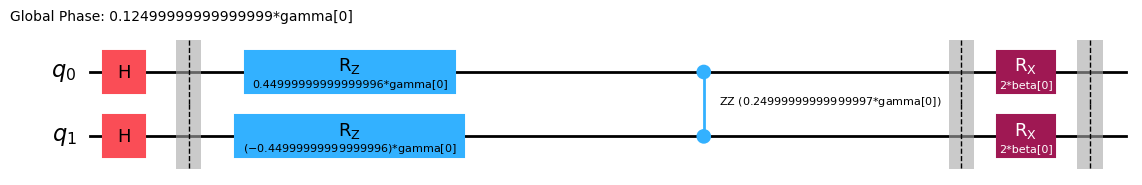


FINAL ACHIEVED W_B VALUES (W_B > 1.0 certifies entanglement)
  backend=ideal  objective=energy   final W_B =   0.2470  -> [not entangled]
  backend=ideal  objective=witness  final W_B =   1.8722  -> [ENTANGLED]
  backend=noisy  objective=energy   final W_B =   0.2446  -> [not entangled]
  backend=noisy  objective=witness  final W_B =   1.8428  -> [ENTANGLED]


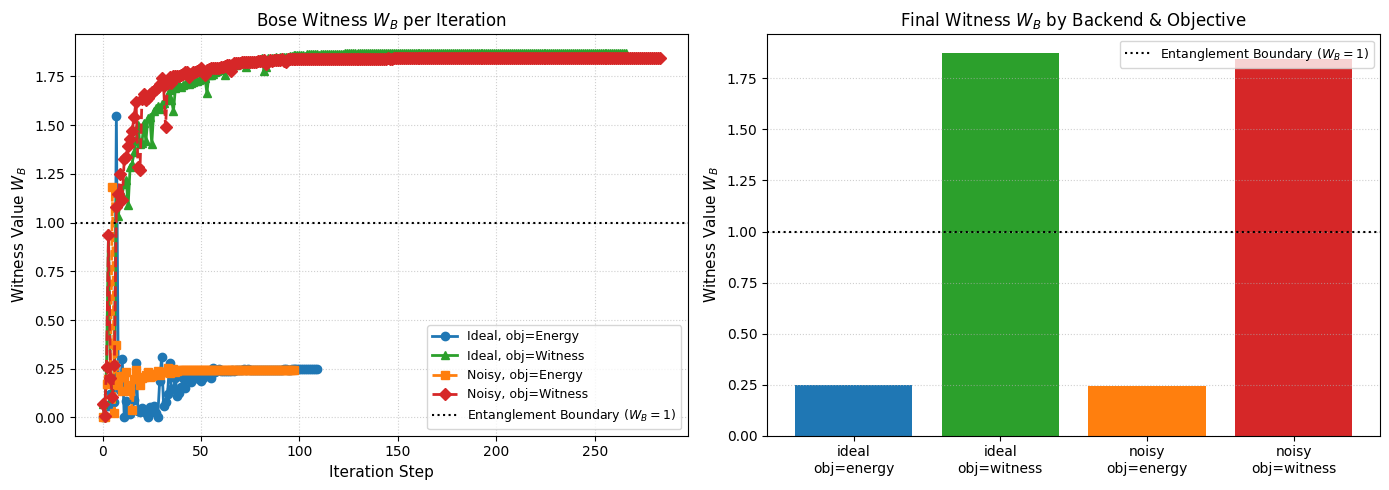

In [11]:
# §4: sweep targeting W_B directly
witness_ops_B = list(build_bose_witness_operators())          # [op_xz, op_yy]
combine_B = lambda evs: abs(evs[0] + evs[1])                  # true W_B = |<XZ> + <YY>|
objective_B = lambda w: -w                                    # maximize W_B by minimizing -W_B

histories_B, results_B, qaoa_template_B = run_witness_sweep(
    cost_h, witness_ops_B, combine_B, witness_to_objective=objective_B
)

display(qaoa_template_B.draw('mpl', style='iqp', fold=False))
print_witness_summary(histories_B, witness_name="W_B", threshold=1.0, entangled_when_greater=True)
plot_witness_sweep(histories_B, witness_name="W_B", threshold=1.0, title_prefix="Bose")

**Reading these results:** minimizing $\langle H_C\rangle$ alone does *not* reliably land on an entangled state — both the ideal (`0.2470`) and noisy (`0.2446`) energy-objective runs converge close to, but not exactly at, the fixed physical target state's own $W_B=0.297$ (COBYLA drifts slightly off $(\gamma,\beta)=(1,0)$ because that point is not actually the *minimum* of $\langle H_C\rangle$ over this ansatz — it's just the point that reproduces the physical state exactly). Either way, both stay well under the $W_B=1$ threshold, exactly as in the discrepancy note above.

Explicitly maximizing $W_B$ instead pushes both runs past the threshold — `1.8722` (ideal) and `1.8428` (noisy) — a striking result: noise barely moves the achievable witness at all once QAOA is allowed to search for it directly, rather than being handed a fixed $(\gamma,\beta)$ point and hoping it survives the noise model unscathed.

## 5. Repeating with $W_S$

The same QAOA search — energy vs. witness objective, ideal vs. noisy backend — repeated with the Struyve/Chevalier–Paige–Kim witness $W_S$ instead of $W_B$. The mechanics are identical (same ansatz, same optimizer, same four-run sweep from §4); only the witness operator and its entanglement threshold change: minimizing $W_S$ directly (rather than $-|W_B|$) is enough here, since $W_S<0$ is itself the entangled regime, so no sign flip is needed for the "witness" objective. This also doubles as a consistency check: if §4 and §5 point to noticeably different optimal $(\gamma,\beta)$, that's a sign the two witnesses aren't just constant offsets of each other on this ansatz.


FINAL ACHIEVED W_S VALUES (W_S < 0.0 certifies entanglement)
  backend=ideal  objective=energy   final W_S =   1.1353  -> [not entangled]
  backend=ideal  objective=witness  final W_S =  -0.3087  -> [ENTANGLED]
  backend=noisy  objective=energy   final W_S =   0.7043  -> [not entangled]
  backend=noisy  objective=witness  final W_S =  -0.2933  -> [ENTANGLED]


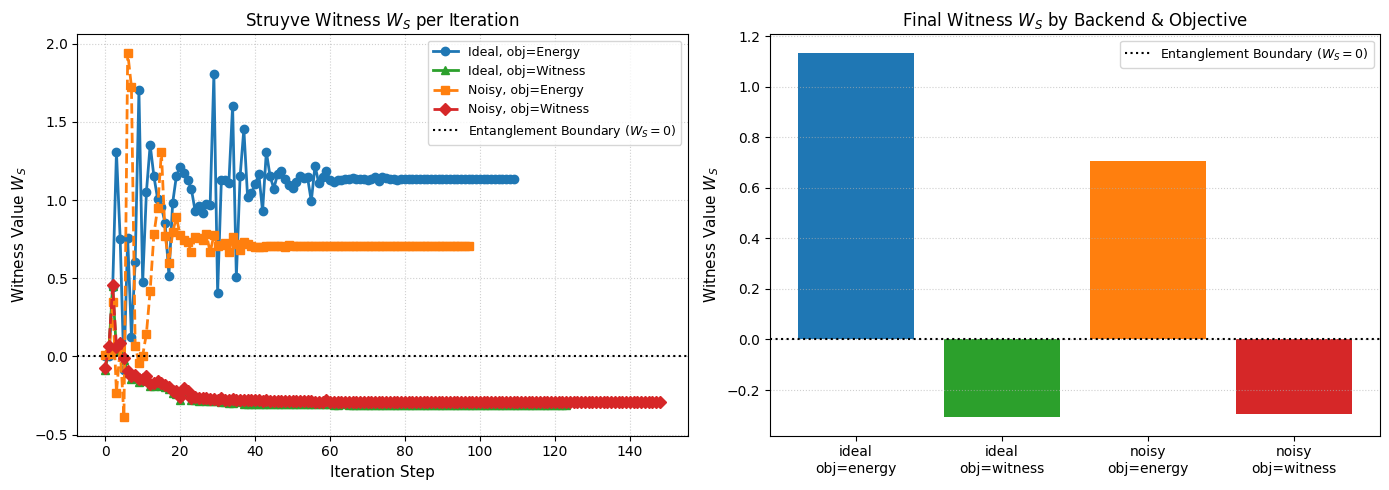

In [12]:
# §5: sweep targeting W_S directly
witness_ops_S = [build_struyve_witness_operator()]            # single combined operator
combine_S = lambda evs: evs[0]                                # true W_S = <I x I - XX - YZ - ZY>
objective_S = lambda w: w                                     # minimize W_S directly (drive it < 0)

histories_S, results_S, qaoa_template_S = run_witness_sweep(
    cost_h, witness_ops_S, combine_S, witness_to_objective=objective_S
)

print_witness_summary(histories_S, witness_name="W_S", threshold=0.0, entangled_when_greater=False)
plot_witness_sweep(histories_S, witness_name="W_S", threshold=0.0, title_prefix="Struyve")

**Reading these results:** the pattern repeats with $W_S$, though the numbers tell a slightly different story. The energy-objective runs land at $W_S\approx1.14$ (ideal) and $\approx0.70$ (noisy) — both comfortably on the *separable* side of the $W_S<0$ threshold, unlike $W_B$'s energy-objective runs in §4, which at least stayed in the same ballpark as the (weakly entangled-by-$W_S$) physical target state. This is consistent with the point made above: energy minimization has no reason to preserve *any particular* witness value, so which side of which threshold it happens to land on is incidental to the objective it's actually solving.

The witness-objective runs, by contrast, again cross into the entangled regime on both backends ($W_S\approx-0.31$ ideal, $-0.29$ noisy) — reinforcing §4's conclusion from a second, independently motivated witness: directly optimizing for entanglement, rather than for energy, is what makes the result robust to noise.

With both witnesses now demonstrated on the same ansatz and the same noise model — and both showing that entanglement is reachable and noise-resilient once QAOA targets the witness directly rather than the cost energy — we have a self-consistent, cross-checked picture of the Bose gravitationally-induced-entanglement circuit. See the appendix below for how this connects to the broader debate over what such an experiment would (and wouldn't) prove about the quantum nature of gravity.

## Appendix: Is the Döner–Großardt Counterexample Real? (Struyve, 2026)

[Struyve](https://iopscience.iop.org/article/10.1088/1751-8121/ae5eb4) revisits exactly the counterexample cited in §0.5 and argues it does not hold up. The argument is short and worth internalizing, since it changes what this notebook series should build next.

**The general result.** Struyve shows that *any* potential of the additively-separable form
$$
V(x,t;\psi_t,Q_t)=\sum_{i=1}^N V_i(\mathbf{x}_i,t;\psi_t,Q_t)
$$
— i.e. a sum of single-particle terms, even if each term depends nonlinearly on the *global* wave function $\psi_t$ or trajectory $Q_t$ — **cannot generate entanglement**. An initially separable state stays separable for all time, because at each instant the multi-particle Schrödinger equation factorizes into independent single-particle equations (freeze the wave function/trajectory dependence at each instant,
solve, then let it evolve self-consistently — the tensor-product structure survives throughout). This covers the Newton–Schrödinger (NS) model, its Bohmian analogue (NSB), a GRW-flash analogue, **and** the interpolating model $V_R$ that Döner & Großardt proposed as their counterexample — all of these potentials are additively separable in exactly this sense.

**Where the error creeps in.** So why did Döner & Großardt conclude their model entangles? Struyve traces it to how the phase on each branch of the recombined interferometer state is computed. On a single run, the Bohmian configuration $(X_{1,t},X_{2,t})$ settles into (approximately) *one* fixed pair of branch centers $(X_{1m},X_{2n})$ — that's the actual trajectory nature ran that shot. The correct
calculation therefore gives, for that run, a single, separable two-qubit state
$$
|\psi_t^{mn}\rangle=\tfrac12\sum_{k,l=L,R}e^{-i\Delta_{kl}^{mn}t/\hbar}|k\rangle_1|l\rangle_2,\qquad
\Delta_{kl}^{mn}=\widetilde V_{R,1}(X_{1k};\psi_0,X_{2n})+\widetilde V_{R,2}(X_{2l};\psi_0,X_{1m}),
$$
which *is* separable because $\Delta_{kl}^{mn}$ is additively separable in $k$ and $l$ once $(m,n)$ is fixed. Döner & Großardt's calculation instead builds a *single* four-term state $|\psi_t\rangle=\tfrac12\sum_{k,l}e^{-i\Delta_{kl}^{kl}t/\hbar}|k\rangle_1|l\rangle_2$ in which the branch-pair used to *evaluate* the phase varies term-by-term along with $(k,l)$ itself — i.e. it silently swaps in a different trajectory configuration for each of the four amplitudes, rather than holding $(X_{1m},X_{2n})$ fixed across all four. That mixed-configuration object is generically entangled, but it isn't the state the dynamics actually produces on any single run; the physical ensemble is a *statistical mixture* over the four (separable) $|\psi_t^{mn}\rangle$, each with probability $1/4$ — and a mixture of separable states is not entangled, even though its per-shot outcome statistics can be nontrivial.

**Practical upshot for this notebook series.** §0.5 promised a follow-up notebook implementing the finite-$R$ hybrid model to compare against the quantized-gravity circuit built here. Given Struyve's correction, that follow-up should **not** be framed as "here is a validated classical alternative that also gives $W>1$" — per this critique it doesn't, once the phase bookkeeping is done per-trajectory rather than per-branch. It would still be a worthwhile companion notebook, but reframed as a worked illustration of *why* the naive per-branch calculation is wrong and how the LOCC argument survives this particular challenge — i.e. a consistency check on the logic in §0.3, not a counterexample to it.

For reference, Struyve also reports closed-form witness curves $W_N(t)$, $W_{NS}(t)$, and $W_{NSB}(t)$ for the Bose experiment's parameters ($d = 450\,\mu\text{m}$, $\delta = 250\,\mu\text{m}$, and $m_1 = m_2 = 10^{-14}\,\text{kg}$) using the [Chevalier-Paige-Kim](https://arxiv.org/abs/2005.13922) witness:
$$
\begin{equation}
    \widehat{W} = I \otimes I - \sigma_x \otimes \sigma_x - \sigma_y \otimes \sigma_z - \sigma_z \otimes \sigma_y
\end{equation}
$$
(Note: $W < 0$ signals entanglement in that convention, which has the opposite sign convention from the $W = |\langle XZ \rangle + \langle YY \rangle| > 1$ criterion used in this notebook.) Only $W_N$, derived from the genuine (non-separable) Newtonian potential, goes negative; $W_{NS}$ and $W_{NSB}$ remain $\ge 0$ throughout, consistent with the general no-entanglement result above. As a preliminary note, we will later evaluate the witness using both the Bose et al.'s $W=|\langle XZ\rangle+\langle YY\rangle|$ and Struyve/Chevalier's $W_S=\langle I\otimes I-XX-YZ-ZY\rangle$ approaches to cross-check the values reported in both papers.